### 01 - AIS Data Exploration & Cleaning

This notebook discovers and validates the monthly AIS files, handles CSVs with and without headers, removes malformed/incomplete records, checks temporal coverage and spatial coordinates, and saves a standardized dataset.

**Annual files such as `2012.csv` are excluded. Only `fYYYY_M.csv` monthly files are used.**

### 1. Imports

In [7]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

### 2. Data location

In [8]:
DATA_ROOT = Path("../AIS/Data/Yearly")
print("Data root:", DATA_ROOT.resolve())
print("Exists:", DATA_ROOT.exists())

Data root: D:\ResearchPapers\AIS_Data_Analysis\AIS\Data\Yearly
Exists: True


### 3. Discover monthly files

In [9]:
EXPECTED_COLUMNS = ["date", "cell_ll_lat", "cell_ll_lon", "mmsi", "hours", "fishing_hours"]
MONTHLY_PATTERN = re.compile(r"^f(\d{4})_(\d{1,2})\.csv$")
monthly_files = []
for path in DATA_ROOT.glob("*/*.csv"):
    match = MONTHLY_PATTERN.match(path.name)
    if match:
        year, month = int(match.group(1)), int(match.group(2))
        if 1 <= month <= 12:
            monthly_files.append({"year":year,"month":month,"path":path})
file_manifest = pd.DataFrame(monthly_files).sort_values(["year","month"]).reset_index(drop=True)
print("Total monthly files:", len(file_manifest))
display(file_manifest.head())
display(file_manifest.tail())

Total monthly files: 147


,year,month,path
0,2012,2,..\AIS\Data\Yearly\2012\f2012_2.csv
1,2012,3,..\AIS\Data\Yearly\2012\f2012_3.csv
2,2012,4,..\AIS\Data\Yearly\2012\f2012_4.csv
3,2012,5,..\AIS\Data\Yearly\2012\f2012_5.csv
4,2012,6,..\AIS\Data\Yearly\2012\f2012_6.csv


,year,month,path
142,2024,8,..\AIS\Data\Yearly\2024\f2024_8.csv
143,2024,9,..\AIS\Data\Yearly\2024\f2024_9.csv
144,2024,10,..\AIS\Data\Yearly\2024\f2024_10.csv
145,2024,11,..\AIS\Data\Yearly\2024\f2024_11.csv
146,2024,12,..\AIS\Data\Yearly\2024\f2024_12.csv


### 4. Temporal coverage

In [10]:
coverage = file_manifest.assign(present=True).pivot(index="year", columns="month", values="present").fillna(False)
display(coverage.astype(int))

for year, group in file_manifest.groupby("year"):
    available = sorted(group["month"].tolist())
    missing = sorted(set(range(1, 13)) - set(available))

    print(
        f"{year}: {len(available)} months | "
        f"available = {available} | missing = {missing}"
    )

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2012,0,1,1,1,1,1,1,1,1,1,1,1
2013,0,1,1,1,1,1,1,1,1,0,0,0
2014,0,0,0,1,1,1,1,1,1,1,1,1
2015,1,1,1,1,1,1,1,1,1,1,1,1
2016,1,1,1,1,1,1,1,1,1,1,1,1
2017,1,1,1,1,1,1,1,1,1,0,1,1
2018,1,1,1,1,1,1,1,1,1,1,1,1
2019,1,1,1,1,1,1,1,1,1,1,1,1
2020,1,1,1,1,1,1,1,1,1,1,1,1


2012: 11 months | available = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | missing = [1]
2013: 8 months | available = [2, 3, 4, 5, 6, 7, 8, 9] | missing = [1, 10, 11, 12]
2014: 9 months | available = [4, 5, 6, 7, 8, 9, 10, 11, 12] | missing = [1, 2, 3]
2015: 12 months | available = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | missing = []
2016: 12 months | available = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | missing = []
2017: 11 months | available = [1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12] | missing = [10]
2018: 12 months | available = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | missing = []
2019: 12 months | available = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | missing = []
2020: 12 months | available = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | missing = []
2021: 12 months | available = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | missing = []
2022: 12 months | available = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | missing = []
2023: 12 months | available = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | mis

### 5. Detect CSV format

In [11]:
def has_expected_header(path):
    try:
        return list(pd.read_csv(path, nrows=0).columns) == EXPECTED_COLUMNS
    except Exception:
        return False

file_manifest["has_header"] = file_manifest["path"].apply(has_expected_header)
print("Files with header:", int(file_manifest["has_header"].sum()))
print("Files without header:", int((~file_manifest["has_header"]).sum()))

Files with header: 141
Files without header: 6


### 6. Clean one monthly file

In [12]:
def clean_monthly_file(path, expected_year, expected_month):
    if has_expected_header(path):
        df = pd.read_csv(path)
    else:
        df = pd.read_csv(path, header=None, names=EXPECTED_COLUMNS)
    df = df[EXPECTED_COLUMNS].copy()
    df["date"] = pd.to_datetime(df["date"], format="mixed", dayfirst=True, errors="coerce")
    for col in ["cell_ll_lat","cell_ll_lon","mmsi","hours","fishing_hours"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.loc[df[EXPECTED_COLUMNS].notna().all(axis=1)].copy()
    df["file_year"] = expected_year
    df["file_month"] = expected_month
    return df

### 7. Load and standardize all monthly files

In [13]:
frames = []
validation = []
for _, row in file_manifest.iterrows():
    raw = pd.read_csv(row["path"], header=0 if row["has_header"] else None, names=None if row["has_header"] else EXPECTED_COLUMNS)
    temp = clean_monthly_file(row["path"], row["year"], row["month"])
    frames.append(temp)
    validation.append({"file_year":row["year"],"file_month":row["month"],"file":row["path"].name,"raw_rows":len(raw),"rows_after_cleaning":len(temp),"dropped_malformed_rows":len(raw)-len(temp)})
ais = pd.concat(frames, ignore_index=True)
ais["year"] = ais["date"].dt.year
ais["month"] = ais["date"].dt.month
ais["day"] = ais["date"].dt.day
validation = pd.DataFrame(validation)
print("Combined shape:", ais.shape)
display(ais.head())

Combined shape: (730488, 11)


,date,cell_ll_lat,cell_ll_lon,mmsi,hours,fishing_hours,file_year,file_month,year,month,day
0,2012-02-26,13.8,80.3,419900160.0,11.9516,11.9516,2012,2,2012,2,26
1,2012-02-27,13.3,80.4,419900160.0,11.7252,11.7252,2012,2,2012,2,27
2,2012-02-25,15.2,80.7,419900160.0,11.7252,11.7252,2012,2,2012,2,25
3,2012-02-26,14.4,80.5,419900160.0,11.7166,11.7166,2012,2,2012,2,26
4,2012-02-25,14.4,80.6,419900160.0,10.4722,10.4722,2012,2,2012,2,25


### 8. Validate parsed dates

In [14]:
validation["invalid_dates"] = 0
validation["wrong_year"] = 0
validation["wrong_month"] = 0
for i, row in validation.iterrows():
    temp = ais[(ais["file_year"]==row["file_year"]) & (ais["file_month"]==row["file_month"])]
    validation.loc[i,"invalid_dates"] = int(temp["date"].isna().sum())
    validation.loc[i,"wrong_year"] = int((temp["year"] != row["file_year"]).sum())
    validation.loc[i,"wrong_month"] = int((temp["month"] != row["file_month"]).sum())
validation["status"] = np.where((validation["invalid_dates"]==0)&(validation["wrong_year"]==0)&(validation["wrong_month"]==0),"OK","REVIEW")
display(validation)
print("Files requiring review:", int((validation["status"]!="OK").sum()))

,file_year,file_month,file,raw_rows,rows_after_cleaning,dropped_malformed_rows,invalid_dates,wrong_year,wrong_month,status
0,2012,2,f2012_2.csv,16,16,0,0,0,0,OK
1,2012,3,f2012_3.csv,17,17,0,0,0,0,OK
2,2012,4,f2012_4.csv,102,102,0,0,0,0,OK
3,2012,5,f2012_5.csv,101,101,0,0,0,0,OK
4,2012,6,f2012_6.csv,97,97,0,0,0,0,OK
...,...,...,...,...,...,...,...,...,...,...
142,2024,8,f2024_8.csv,16341,16341,0,0,0,0,OK
143,2024,9,f2024_9.csv,19297,19297,0,0,0,0,OK
144,2024,10,f2024_10.csv,18674,18674,0,0,0,0,OK
145,2024,11,f2024_11.csv,19340,19340,0,0,0,0,OK


Files requiring review: 0


### 9. Basic data-quality checks

In [15]:
print("Missing values:")
display(ais[EXPECTED_COLUMNS].isna().sum())
print("\nDuplicate rows:", int(ais.duplicated().sum()))
print("\nCoordinate ranges:")
print("Latitude:", ais.cell_ll_lat.min(), "to", ais.cell_ll_lat.max())
print("Longitude:", ais.cell_ll_lon.min(), "to", ais.cell_ll_lon.max())
negative_effort = ais[(ais.hours<0)|(ais.fishing_hours<0)]
print("\nNegative effort rows:", len(negative_effort))
display(ais[["hours","fishing_hours"]].describe())

Missing values:


date             0
cell_ll_lat      0
cell_ll_lon      0
mmsi             0
hours            0
fishing_hours    0
dtype: int64


Duplicate rows: 78

Coordinate ranges:
Latitude: -29.2 to 40.0
Longitude: 32.0 to 161.9

Negative effort rows: 0


,hours,fishing_hours
count,730488.000000,730488.000000
mean,4.749365,4.190965
std,5.592289,5.230988
min,0.000500,0.000500
25%,1.080500,0.842200
50%,2.329400,1.967700
75%,6.286025,5.374100
max,46.755000,46.755000


### 10. Check the native spatial grid

In [16]:
invalid_coordinates = ais[(ais.cell_ll_lat < -90)|(ais.cell_ll_lat > 90)|(ais.cell_ll_lon < -180)|(ais.cell_ll_lon > 180)]
print("Invalid coordinates:", len(invalid_coordinates))
lat_values = np.sort(ais.cell_ll_lat.dropna().unique())
lon_values = np.sort(ais.cell_ll_lon.dropna().unique())
print("Unique latitudes:", len(lat_values))
print("Unique longitudes:", len(lon_values))
print("\nLatitude spacings:")
display(pd.Series(np.round(np.diff(lat_values),6)).value_counts().head(10))
print("\nLongitude spacings:")
display(pd.Series(np.round(np.diff(lon_values),6)).value_counts().head(10))

Invalid coordinates: 0
Unique latitudes: 474
Unique longitudes: 549

Latitude spacings:


0.1     457
0.3       5
0.2       5
0.5       2
17.4      1
1.2       1
0.8       1
0.6       1
Name: count, dtype: int64


Longitude spacings:


0.1     529
0.2       8
0.4       3
20.9      1
10.3      1
5.5       1
4.7       1
0.3       1
1.8       1
22.6      1
Name: count, dtype: int64

### 11. Spatial summary

In [17]:
spatial_summary = ais.groupby(["cell_ll_lat","cell_ll_lon"], as_index=False).agg(total_hours=("hours","sum"), total_fishing_hours=("fishing_hours","sum"), active_vessels=("mmsi","nunique"))
display(spatial_summary.sort_values("total_fishing_hours", ascending=False).head(20))

,cell_ll_lat,cell_ll_lon,total_hours,total_fishing_hours,active_vessels
10389,12.8,74.6,26798.2985,22251.9623,643
10199,12.7,74.6,23277.4537,19797.9999,605
10009,12.6,74.7,21519.3890,17814.9795,538
10200,12.7,74.7,20101.9084,16075.3184,561
10593,12.9,74.5,17253.8147,15299.7211,604
10794,13.0,74.5,16330.4397,14779.8596,584
10008,12.6,74.6,16602.9253,14258.7287,535
10594,12.9,74.6,17098.1450,14179.4949,627
10991,13.1,74.5,15774.4992,14160.6571,549
10795,13.0,74.6,16465.2440,13833.8764,576


### 12. Spatial effort visualization

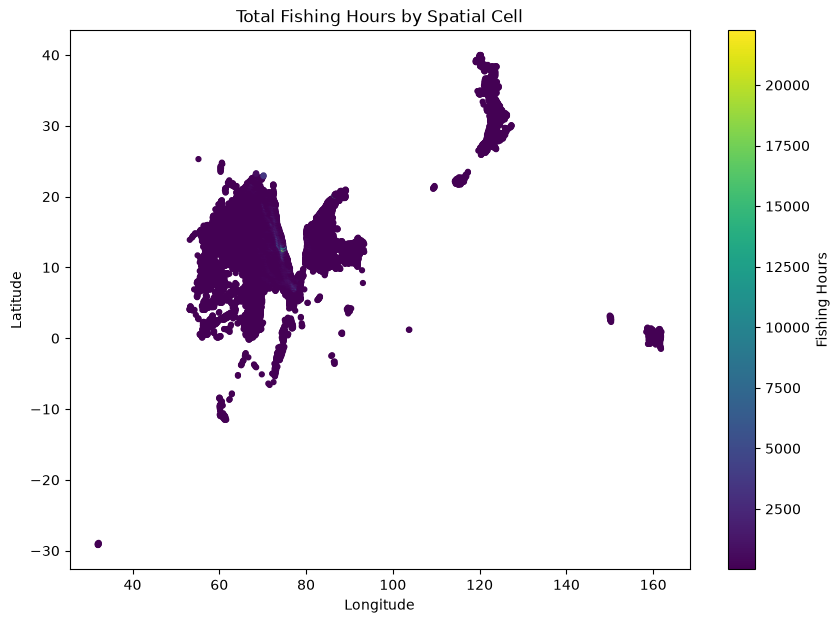

In [18]:
plt.figure(figsize=(10,7))
plt.scatter(spatial_summary.cell_ll_lon, spatial_summary.cell_ll_lat, c=spatial_summary.total_fishing_hours, s=12)
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("Total Fishing Hours by Spatial Cell")
plt.colorbar(label="Fishing Hours")
plt.show()

### 13. Save standardized dataset

In [21]:
OUTPUT_DIR = Path("../outputs/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = OUTPUT_DIR / "ais_cleaned.parquet"
ais.to_parquet(OUTPUT_FILE, index=False)
ais.to_csv(OUTPUT_DIR / "ais_cleaned.csv", index= False)
print("Saved:", OUTPUT_FILE.resolve())
print("Rows:", len(ais))

Saved: D:\ResearchPapers\AIS_Data_Analysis\outputs\processed\ais_cleaned.parquet
Rows: 730488


### 14. Final verification

In [20]:
check = pd.read_parquet(OUTPUT_FILE)
print("Reloaded shape:", check.shape)
print("Date range:", check.date.min(), "→", check.date.max())
print("Unique vessels:", check.mmsi.nunique())
print("Unique spatial cells:", check[["cell_ll_lat","cell_ll_lon"]].drop_duplicates().shape[0])

Reloaded shape: (730488, 11)
Date range: 2012-02-15 00:00:00 → 2024-12-31 00:00:00
Unique vessels: 1930
Unique spatial cells: 23846


### Notes for the next stage

- Keep standardized observations at date × cell × MMSI level.
- Use spatial cell × month × year as the main aggregation level.
- Do not fill missing months with zero.
- Use `fishing_hours` as the primary fishing-effort metric.
- The source data was already filtered to fishing-active observations.